# DQN - Acrobot: balancear el doble pendulo en el equilibrio inestable

Cambios respecto al Acrobot-v1 original:

- **Acciones**: 7 torques discretos equiespaciados entre `-max_torque` y `+max_torque` (en vez de -1, 0, +1).
- **Recompensa**: depende de la altura de la punta, `h = -cos(theta1) - cos(theta1 + theta2)` (`h = -2` colgando, `h = +2` completamente erguido). Se suma un bonus de balanceo cuando esta cerca de la vertical y con poca velocidad.
- **Sin terminacion al superar la altura**: el episodio solo termina por limite de tiempo (truncation), asi que el agente tiene que *mantenerse* arriba.
- **Observacion**: `[cos th1, sin th1, cos th2, sin th2, w1/(4pi), w2/(9pi)]` (velocidades normalizadas a [-1, 1]).
- **Inicio aleatorio (solo entrenamiento)**: con cierta probabilidad el episodio arranca en un estado aleatorio, para que el agente vea estados cercanos a la vertical desde temprano.

In [95]:
import os
import random
import time

from dataclasses import dataclass

import gymnasium as gym
from gymnasium import spaces
from gymnasium.envs.classic_control.acrobot import AcrobotEnv, wrap, bound

import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.tensorboard import SummaryWriter

from cleanrl_utils.buffers import ReplayBuffer

import matplotlib.pyplot as plt

In [ ]:
# HIPERPARAMETROS
@dataclass
class Args:
    exp_name: str = 'dqn_acrobot_balance'
    seed: int = 1
    torch_deterministic: bool = True
    cuda: bool = False
    track: bool = False

    wandb_project_name: str = 'cleanRL'
    wandb_entity: str = None

    capture_video: bool = False
    save_model: bool = False
    upload_model: bool = False
    hf_entity: str = ''

    # Entorno
    env_id: str = 'AcrobotBalance'
    n_torques: int = 9
    max_torque: float = 2.0
    max_episode_steps: int = 500
    random_init_prob: float = 0.15    # prob. de arrancar en un estado aleatorio (solo entrenamiento)
    upright_init_prob: float = 0.35   # prob. de arrancar cerca de la vertical (solo entrenamiento)

    # Algorithm specific arguments
    total_timesteps: int = 1_000_000
    learning_rate: float = 1e-4
    num_envs: int = 1
    buffer_size: int = 500_000
    gamma: float = 0.995
    tau: float = 0.005
    target_network_frequency: int = 4
    batch_size: int = 256
    start_e: float = 1.0 
    end_e: float = 0.02  
    exploration_fraction: float = 0.25
    learning_starts: int = 10_000
    train_frequency: int = 4


args = Args()

In [119]:
def rk4(derivs, y0, t):
    y = np.asarray(y0, dtype=np.float64)
    for i in range(len(t) - 1):
        dt = t[i + 1] - t[i]
        dt2 = dt / 2.0
        k1 = np.asarray(derivs(y))
        k2 = np.asarray(derivs(y + dt2 * k1))
        k3 = np.asarray(derivs(y + dt2 * k2))
        k4 = np.asarray(derivs(y + dt * k3))
        y = y + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y[:4]   # solo el estado (sin el torque aumentado)


# Entorno Acrobot modificado: torques geométricos, dt fino, obs de 8 dim y recompensa convexa
class AcrobotBalanceEnv(AcrobotEnv):

    def __init__(self, n_torques=9, max_torque=2.0, random_init_prob=0.0, upright_init_prob=0.0, render_mode=None):
        super().__init__(render_mode=render_mode)

        # Cambio 2: período de control más fino y subpasos RK4
        self.dt = 0.1
        self.n_substeps = 4

        # Cambio 3: discretización geométrica consistente con n_torques y max_torque
        assert n_torques % 2 == 1, "n_torques debe ser impar"
        half = n_torques // 2
        mags = max_torque * np.geomspace(0.05, 1.0, half)
        self.AVAIL_TORQUE = np.concatenate([-mags[::-1], [0.0], mags])
        self.action_space = spaces.Discrete(n_torques)

        # Cambio 4: observación de 8 dimensiones (incluye ángulo de la punta y velocidades con tanh)
        self.observation_space = spaces.Box(
            low=-1.0, high=1.0, shape=(8,), dtype=np.float32
        )

        # Cambio 1: probabilidades de inicialización
        self.random_init_prob = random_init_prob
        self.upright_init_prob = upright_init_prob

    def _get_ob(self):
        th1, th2, w1, w2 = self.state
        tip = th1 + th2
        return np.array(
            [
                np.cos(th1), np.sin(th1),
                np.cos(th2), np.sin(th2),
                np.cos(tip), np.sin(tip),
                np.tanh(w1 / 3.0),
                np.tanh(w2 / 4.0),
            ],
            dtype=np.float32,
        )

    @staticmethod
    def tip_height(s):
        # -2 = colgando hacia abajo, +2 = completamente vertical hacia arriba
        return -np.cos(s[0]) - np.cos(s[0] + s[1])

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed, options=options)
        u = self.np_random.random()

        if u < self.upright_init_prob:                            # cerca de la cima
            th1 = np.pi + self.np_random.normal(0, 0.2)
            th2 = self.np_random.normal(0, 0.2)
            w   = self.np_random.normal(0, 0.3, size=2)
            self.state = np.array([wrap(th1, -np.pi, np.pi),
                                   wrap(th2, -np.pi, np.pi),
                                   w[0], w[1]], dtype=np.float32)

        elif u < self.upright_init_prob + self.random_init_prob:  # aleatorio
            self.state = self.np_random.uniform(
                low=[-np.pi, -np.pi, -1.0, -1.0],
                high=[np.pi,  np.pi,  1.0,  1.0]).astype(np.float32)
        # si no: arranque colgando (default de Acrobot)
        return self._get_ob(), {}

    def step(self, a):
        s = self.state
        assert s is not None, 'Llamar a reset() antes de step()'

        torque = self.AVAIL_TORQUE[a]

        if self.torque_noise_max > 0:
            torque += self.np_random.uniform(-self.torque_noise_max, self.torque_noise_max)

        # Integracion de la dinamica con n_substeps
        s_augmented = np.append(s, torque)
        ns = rk4(self._dsdt, s_augmented, np.linspace(0, self.dt, self.n_substeps + 1))

        ns[0] = wrap(ns[0], -np.pi, np.pi)
        ns[1] = wrap(ns[1], -np.pi, np.pi)
        ns[2] = bound(ns[2], -self.MAX_VEL_1, self.MAX_VEL_1)
        ns[3] = bound(ns[3], -self.MAX_VEL_2, self.MAX_VEL_2)
        self.state = ns

        # ---------- Cambio 5: Recompensa menos explotable ----------
        th1, th2, dth1, dth2 = self.state
        height = -np.cos(th1) - np.cos(th1 + th2)
        vel_norm = abs(dth1) + abs(dth2)

        reward = ((height + 2.0) / 4.0) ** 2          # convexa: premia mucho más estar arriba
        if height > 1.5:                              # zona de balanceo
            progress = (height - 1.5) / 0.5
            reward += 2.0 * progress * np.exp(-0.5 * vel_norm)
        reward -= 0.01 * (torque ** 2)
        reward *= 0.33                                # |r| <~ 1  -> Q máx ~ 200

        balanced = bool(height > 1.8 and vel_norm < 1.0)
        info = {'height': float(height), 'balanced': balanced}

        if self.render_mode == 'human':
            self.render()

        # Nunca termina: solo se trunca por limite de tiempo (TimeLimit)
        return self._get_ob(), reward, False, False, info

In [120]:
# Crear el entorno
def make_env(seed, idx, capture_video, run_name, random_init_prob=0.0, upright_init_prob=0.0):

    def thunk():

        render_mode = 'rgb_array' if (capture_video and idx == 0) else None

        env = AcrobotBalanceEnv(
            n_torques=args.n_torques,
            max_torque=args.max_torque,
            random_init_prob=random_init_prob,
            upright_init_prob=upright_init_prob,
            render_mode=render_mode,
        )
        env = gym.wrappers.TimeLimit(env, max_episode_steps=args.max_episode_steps)

        if render_mode is not None:
            env = gym.wrappers.RecordVideo(env, f'videos/{run_name}')

        env = gym.wrappers.RecordEpisodeStatistics(env)
        env.action_space.seed(seed)

        return env

    return thunk

In [121]:
# Definir la red neuronal
class QNetwork(nn.Module):

    def __init__(self, env):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(
                np.array(env.single_observation_space.shape).prod(),
                256
            ),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(
                256,
                env.single_action_space.n
            ),
        )

    def forward(self, x):
        return self.network(x)

In [122]:
# Funcion de exploracion
def linear_schedule(start_e, end_e, duration, t):

    slope = (end_e - start_e) / duration

    return max(slope * t + start_e, end_e)

In [ ]:
# Inicializar el entrenamiento
# Nombre de la ejecucion
run_name = f'{args.env_id}__{args.exp_name}__{args.seed}__{int(time.time())}'

# Directorio de resultados
os.makedirs(f'runs/{run_name}', exist_ok=True)

# Inicializar TensorBoard
writer = SummaryWriter(f'runs/{run_name}')

# Fijar semillas aleatorias
random.seed(args.seed)
np.random.seed(args.seed)
torch.manual_seed(args.seed)

torch.backends.cudnn.deterministic = args.torch_deterministic

# Seleccionar dispositivo
device = torch.device(
    'cuda' if torch.cuda.is_available() and args.cuda else 'cpu'
)

print('Dispositivo seleccionado:', device)

# Crear entorno (con inicios aleatorios y cerca de la cima para entrenar)
envs = gym.vector.SyncVectorEnv(
    [
        make_env(
            args.seed + i,
            i,
            args.capture_video,
            run_name,
            random_init_prob=args.random_init_prob,
            upright_init_prob=args.upright_init_prob
        )
        for i in range(args.num_envs)
    ]
)

assert isinstance(
    envs.single_action_space,
    gym.spaces.Discrete
)

print('Acciones:', envs.single_action_space.n)
print('Torques:', np.round(envs.envs[0].unwrapped.AVAIL_TORQUE, 2))

# Crear red neuronal principal
q_network = QNetwork(envs).to(device)

optimizer = optim.Adam(
    q_network.parameters(),
    lr=args.learning_rate
)

# Crear red neuronal objetivo
target_network = QNetwork(envs).to(device)

target_network.load_state_dict(
    q_network.state_dict()
)

# Crear Replay Buffer
rb = ReplayBuffer(
    args.buffer_size,
    envs.single_observation_space,
    envs.single_action_space,
    device,
    handle_timeout_termination=False  ## En el target del paso 500, el valor esperado futuro será 0: T_500= R_500. Introduce sesgo.
)

# Reiniciar entorno
obs, _ = envs.reset(seed=args.seed)

# Variables para registrar resultados
start_time = time.time()
episodic_returns = []

print('Inicializacion completada.')

Dispositivo seleccionado: cpu
Acciones: 9
Torques: [-2.   -0.74 -0.27 -0.1   0.    0.1   0.27  0.74  2.  ]
Inicializacion completada.


In [ ]:
# Ejecutar entrenamiento DQN
best_score = -np.inf

for global_step in range(args.total_timesteps):

    # ---------------------------------
    # 1. Seleccion de acciones
    # ---------------------------------
    epsilon = linear_schedule(    # la probabilidad de explorar decae linealmente durante el primer 25% de 1millón de pasos, después queda en 0.02
        args.start_e,
        args.end_e,
        args.exploration_fraction * args.total_timesteps,
        global_step
    )

    if random.random() < epsilon: # con proba epsilon, elijo una acción al azar
        actions = np.array([
            envs.single_action_space.sample()
            for _ in range(envs.num_envs)
        ])
    else: # con proba 1-epsilon, elijo la acción de mayor valor
        with torch.no_grad():
            q_values = q_network(torch.Tensor(obs).to(device))
            actions = torch.argmax(q_values, dim=1).cpu().numpy()

    # ---------------------------------
    # 2. Ejecutar acciones
    # ---------------------------------
    next_obs, rewards, terminations, truncations, infos = envs.step(actions)

    # ---------------------------------
    # 3. Registrar recompensas
    # ---------------------------------
    if 'final_info' in infos:
        for info in infos['final_info']:
            if info and 'episode' in info:
                episode_return = float(np.asarray(info['episode']['r']).item())
                episodic_returns.append(episode_return)

                if len(episodic_returns) % 10 == 0:
                    print(
                        f'global_step={global_step}, '
                        f'episodios={len(episodic_returns)}, '
                        f'epsilon={epsilon:.2f}, '
                        f'retorno (ult. 10)={np.mean(episodic_returns[-10:]):.1f}'
                    )

                writer.add_scalar(
                    'charts/episodic_return',
                    episode_return,
                    global_step
                )

    # ---------------------------------
    # 4. Guardar experiencias
    # ---------------------------------
    real_next_obs = next_obs.copy()
    for idx, trunc in enumerate(truncations):
        if trunc:
            real_next_obs[idx] = infos['final_observation'][idx]

    rb.add(   #guardamos SARS en el replay buffer 
        obs,
        real_next_obs,
        actions,
        rewards,
        terminations,
        infos
    )

    obs = next_obs

    # ---------------------------------
    # 5. Entrenamiento de la red neuronal
    # ---------------------------------
    if global_step > args.learning_starts:

        if global_step % args.train_frequency == 0:
            data = rb.sample(args.batch_size)

            with torch.no_grad():
                target_max, _ = target_network(
                    data.next_observations
                ).max(dim=1)

                td_target = (
                    data.rewards.flatten()
                    + args.gamma
                    * target_max
                    * (1 - data.dones.flatten())
                )

            old_val = q_network(
                data.observations
            ).gather(
                1,
                data.actions
            ).squeeze()

            loss = F.smooth_l1_loss(old_val, td_target)

            # Registrar metricas
            if global_step % 1000 == 0:
                writer.add_scalar('losses/td_loss', loss.item(), global_step)
                writer.add_scalar('losses/q_values', old_val.mean().item(), global_step)
                sps = int(global_step / (time.time() - start_time))
                writer.add_scalar('charts/SPS', sps, global_step)

            # Optimizar red neuronal con gradient clipping
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(q_network.parameters(), 10.0)
            optimizer.step()

        # ---------------------------------
        # 6. Actualizar target network
        # ---------------------------------
        if global_step % args.target_network_frequency == 0:
            for target_param, q_param in zip(
                target_network.parameters(),
                q_network.parameters()
            ):
                target_param.data.copy_(
                    args.tau * q_param.data
                    + (1.0 - args.tau) * target_param.data
                )

        # ---------------------------------
        # 7. Evaluacion periodica y mejor checkpoint
        # ---------------------------------
        if global_step % 25_000 == 0:
            res = evaluate(q_network, n_episodes=5, verbose=False)   # arranque colgando
            mean_bal = float(np.mean(res['balanced_frac']))
            mean_h = float(np.mean(res['final_height']))
            score = mean_bal + 0.1 * mean_h   # criterio para elegir el mejor modelo: tiempo que pasó balanceandose + altura promedio

            writer.add_scalar('eval/balanced_frac', mean_bal, global_step)
            writer.add_scalar('eval/final_height', mean_h, global_step)

            if score > best_score:
                best_score = score
                torch.save(q_network.state_dict(), f'runs/{run_name}/best.pth')
                print(f'>>> Nuevo mejor modelo en step {global_step}: balanced={100*mean_bal:.1f}%, final_h={mean_h:.2f}')

print('Entrenamiento finalizado.')

global_step=4999, episodios=10, epsilon=0.98, retorno (ult. 10)=32.3
global_step=9999, episodios=20, epsilon=0.96, retorno (ult. 10)=13.8
global_step=14999, episodios=30, epsilon=0.94, retorno (ult. 10)=18.2
global_step=19999, episodios=40, epsilon=0.92, retorno (ult. 10)=14.1
global_step=24999, episodios=50, epsilon=0.90, retorno (ult. 10)=12.6
>>> Nuevo mejor modelo en step 25000: balanced=0.0%, final_h=-0.18
global_step=29999, episodios=60, epsilon=0.88, retorno (ult. 10)=16.0
global_step=34999, episodios=70, epsilon=0.86, retorno (ult. 10)=35.0
global_step=39999, episodios=80, epsilon=0.84, retorno (ult. 10)=31.0
global_step=44999, episodios=90, epsilon=0.82, retorno (ult. 10)=26.6
global_step=49999, episodios=100, epsilon=0.80, retorno (ult. 10)=34.1
>>> Nuevo mejor modelo en step 50000: balanced=0.0%, final_h=0.09
global_step=54999, episodios=110, epsilon=0.78, retorno (ult. 10)=33.2
global_step=59999, episodios=120, epsilon=0.76, retorno (ult. 10)=51.2
global_step=64999, episodi

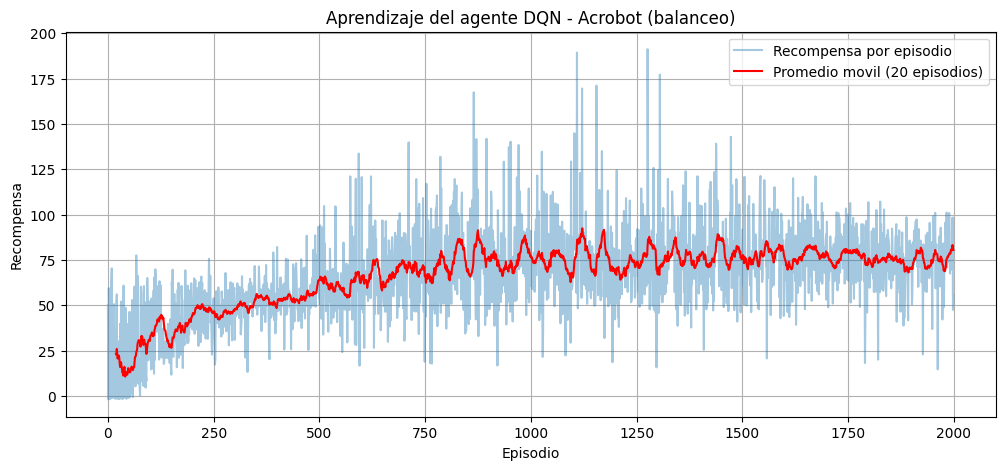

In [125]:
# Visualizar aprendizaje
plt.figure(figsize=(12, 5))

plt.plot(
    episodic_returns,
    alpha=0.4,
    label='Recompensa por episodio'
)

# Promedio movil de 20 episodios
if len(episodic_returns) >= 20:

    moving_average = np.convolve(
        episodic_returns,
        np.ones(20) / 20,
        mode='valid'
    )

    plt.plot(
        range(19, len(episodic_returns)),
        moving_average,
        color='red',
        label='Promedio movil (20 episodios)'
    )

plt.xlabel('Episodio')
plt.ylabel('Recompensa')
plt.title('Aprendizaje del agente DQN - Acrobot (balanceo)')
plt.legend()
plt.grid()

plt.show()

En el episodio mil, se llena el buffer. Quizá agregando espacio en el buffer tarde más en estancarse.

In [115]:
# Guardar los parametros
model_path = f'runs/{run_name}/dqn_model.pth'

os.makedirs(f'runs/{run_name}', exist_ok=True)

torch.save(q_network.state_dict(), model_path)

print('Modelo guardado en:', model_path)

Modelo guardado en: runs/AcrobotBalance__dqn_acrobot_balance__1__1794704303/dqn_model.pth


In [117]:
# Cerrar entorno
# IMPORTANTE: primero guardar los parametros
envs.close()
writer.close()

In [126]:
# Cargar el mejor checkpoint guardado durante el entrenamiento y evaluar
best_model_path = f'runs/{run_name}/best.pth'
if os.path.exists(best_model_path):
    q_network.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
    print(f'Cargado mejor modelo desde: {best_model_path}')

q_network.eval()
eval_results = evaluate(q_network, n_episodes=20, verbose=True)

Cargado mejor modelo desde: runs/AcrobotBalance__dqn_acrobot_balance__1__1794707812/best.pth
Episodio 1: recompensa = 49.5, altura final media = 0.39, balanceado = 0% del episodio
Episodio 2: recompensa = 86.4, altura final media = 0.33, balanceado = 6% del episodio
Episodio 3: recompensa = 63.4, altura final media = 0.29, balanceado = 0% del episodio
Episodio 4: recompensa = 87.6, altura final media = 0.66, balanceado = 10% del episodio
Episodio 5: recompensa = 75.5, altura final media = 0.85, balanceado = 2% del episodio
Episodio 6: recompensa = 87.1, altura final media = 0.82, balanceado = 9% del episodio
Episodio 7: recompensa = 68.9, altura final media = 0.40, balanceado = 0% del episodio
Episodio 8: recompensa = 68.9, altura final media = 0.38, balanceado = 2% del episodio
Episodio 9: recompensa = 28.9, altura final media = -0.29, balanceado = 0% del episodio
Episodio 10: recompensa = 33.1, altura final media = -0.12, balanceado = 0% del episodio
Episodio 11: recompensa = 48.4, a

In [104]:
# Entorno de evaluacion
def make_eval_env(random_init_prob=0.0, upright_init_prob=0.0, render_mode=None):
    env = AcrobotBalanceEnv(
        n_torques=args.n_torques,
        max_torque=args.max_torque,
        random_init_prob=random_init_prob,
        upright_init_prob=upright_init_prob,
        render_mode=render_mode,
    )
    return gym.wrappers.TimeLimit(env, max_episode_steps=args.max_episode_steps)


# Funcion de evaluacion de modelo (politica greedy)
def evaluate(model, n_episodes=20, random_init_prob=0.0, upright_init_prob=0.0, seed=42, verbose=True):
    """
    Corre n_episodes con la politica greedy del modelo.
    Devuelve, por episodio: retorno, altura media de los ultimos 100 pasos
    y fraccion de pasos en que el pendulo estuvo balanceado (h > 1.8 y velocidad baja).
    random_init_prob=0.0 y upright_init_prob=0.0 -> arranca colgando (como Acrobot original).
    """
    env = make_eval_env(random_init_prob=random_init_prob, upright_init_prob=upright_init_prob)
    results = {'returns': [], 'final_height': [], 'balanced_frac': []}

    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        done = False
        total = 0.0
        heights = []
        balanced = []

        while not done:
            with torch.no_grad():
                q_values = model(torch.Tensor(obs).unsqueeze(0).to(device))
            action = torch.argmax(q_values, dim=1).item()

            obs, reward, terminated, truncated, info = env.step(action)
            total += reward
            heights.append(info['height'])
            balanced.append(info['balanced'])
            done = terminated or truncated

        results['returns'].append(total)
        results['final_height'].append(np.mean(heights[-100:]))
        results['balanced_frac'].append(np.mean(balanced))
        if verbose:
            print(
                f'Episodio {ep + 1}: recompensa = {total:.1f}, '
                f'altura final media = {results["final_height"][-1]:.2f}, '
                f'balanceado = {100 * results["balanced_frac"][-1]:.0f}% del episodio'
            )

    env.close()
    return results


--- Resumen ---
Retorno promedio: 142.4 (maximo posible ~ 1600)
Desvio:           49.4
Altura final media: 0.48 (maximo = 2)
Tiempo balanceado:  7.0%


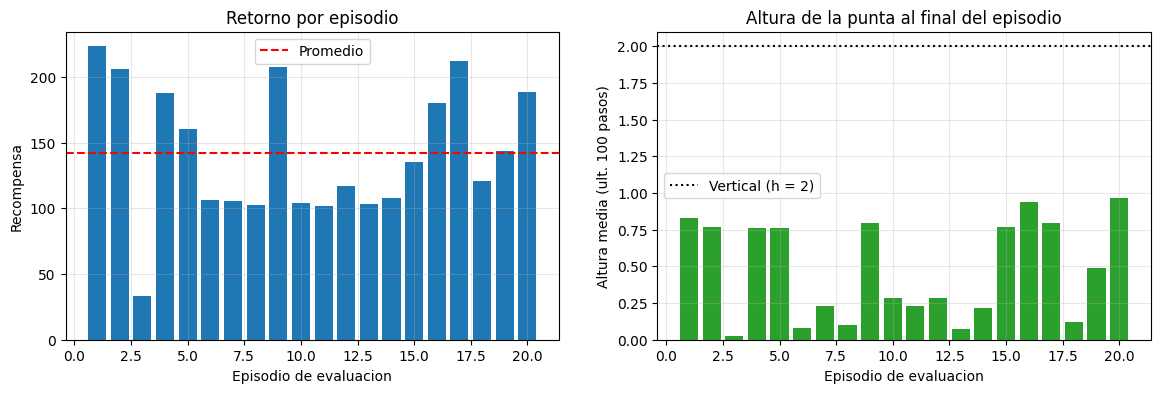

In [111]:
# Visualizar resultados del modelo
eval_returns = eval_results['returns']

print('\n--- Resumen ---')
print(f'Retorno promedio: {np.mean(eval_returns):.1f} (maximo posible ~ {2 * args.max_episode_steps})')
print(f'Desvio:           {np.std(eval_returns):.1f}')
print(f'Altura final media: {np.mean(eval_results["final_height"]):.2f} (maximo = 2)')
print(f'Tiempo balanceado:  {100 * np.mean(eval_results["balanced_frac"]):.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(range(1, len(eval_returns) + 1), eval_returns)
axes[0].axhline(np.mean(eval_returns), color='red', linestyle='--', label='Promedio')
axes[0].set_xlabel('Episodio de evaluacion')
axes[0].set_ylabel('Recompensa')
axes[0].set_title('Retorno por episodio')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(range(1, len(eval_returns) + 1), eval_results['final_height'], color='tab:green')
axes[1].axhline(2.0, color='black', linestyle=':', label='Vertical (h = 2)')
axes[1].set_xlabel('Episodio de evaluacion')
axes[1].set_ylabel('Altura media (ult. 100 pasos)')
axes[1].set_title('Altura de la punta al final del episodio')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.show()

In [114]:
# Crear un video de la politica entrenada
video_env = make_eval_env(render_mode='rgb_array')
video_env = gym.wrappers.RecordVideo(
    video_env,
    video_folder='videos_eval',
    episode_trigger=lambda ep: True,   # graba todos los episodios
)

for ep in range(3):
    obs, _ = video_env.reset(seed=100 + ep)
    done = False
    while not done:
        with torch.no_grad():
            q_values = q_network(torch.Tensor(obs).unsqueeze(0).to(device))
        action = torch.argmax(q_values, dim=1).item()
        obs, reward, terminated, truncated, _ = video_env.step(action)
        done = terminated or truncated

video_env.close()
print("Videos guardados en la carpeta 'videos_eval'.")

MoviePy - Building video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-0.mp4.
MoviePy - Writing video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-0.mp4



MoviePy - Done !
MoviePy - video ready /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-0.mp4
MoviePy - Building video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-1.mp4.
MoviePy - Writing video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-1.mp4



MoviePy - Done !
MoviePy - video ready /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-1.mp4
MoviePy - Building video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-2.mp4.
MoviePy - Writing video /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-2.mp4



MoviePy - Done !
MoviePy - video ready /home/francisco/apRef/ACROBOT DQN/videos_eval/rl-video-episode-2.mp4
Videos guardados en la carpeta 'videos_eval'.
